In [1]:
import cv2
import numpy as np # Añadido para poder medir el color/brillo
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay 

TAREA: Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia impicaríaj en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y mo¡ilímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien 
no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas?
Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc. 



In [2]:
img = cv2.imread('assets/Monedas.jpg')
img_gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
img_th1 = cv2.threshold(img_gris,0,255,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)[1]


#Obtiene únicamente los contornos externos
contornos2, hierarchy2 = cv2.findContours(img_th1,
    cv2.RETR_EXTERNAL ,
    cv2.CHAIN_APPROX_SIMPLE)


contornos_grandes = [c for c in contornos2 if cv2.contourArea(c) >= 100]
print(f"Se han encontrado {len(contornos_grandes)} monedas.")


factor_conversion_1_euro = None 

# Función para capturar el clic del ratón y obtener las coordenadas
def capturar_clic(event, x, y, flags, param):
    global factor_conversion_1_euro
    if event == cv2.EVENT_LBUTTONDOWN:
        for c in contornos_grandes:

            # Vefica si el clic está dentro del contorno
            if cv2.pointPolygonTest(c, (x, y), False) >= 0:

                # Círculo mínimo que contiene al contorno
                __,radio = cv2.minEnclosingCircle(c)
                factor_conversion_1_euro = radio * 2 / 23.25

cv2.namedWindow('Calibracion')
cv2.setMouseCallback('Calibracion', capturar_clic)

cv2.imshow('Calibracion', img)
cv2.waitKey(0)
cv2.destroyAllWindows()


if factor_conversion_1_euro is not None:
    dinero_total = 0.0
    tolerancia = 0.5
    
    for c in contornos_grandes:
        __,radio = cv2.minEnclosingCircle(c)
        diametro = radio * 2 / factor_conversion_1_euro
        if abs(diametro - 25.75) <= tolerancia:
            dinero_total += 2.0
        elif abs(diametro - 23.25) <= tolerancia:
            dinero_total += 1.0
        elif abs(diametro - 24.25) <=  tolerancia:
            dinero_total += 0.5
        elif abs(diametro - 22.25) <= tolerancia:
            dinero_total += 0.2
        elif abs(diametro - 19.75) <= tolerancia:
            dinero_total += 0.1
        elif abs(diametro - 21.25) <= tolerancia:  
            dinero_total += 0.05
        elif abs(diametro - 18.75) <= tolerancia:
            dinero_total += 0.02
        elif abs(diametro - 16.25) <= tolerancia:
            dinero_total += 0.01

print(f"Dinero total: {dinero_total:.2f} euros")
        

Se han encontrado 8 monedas.
Dinero total: 3.88 euros


In [12]:
vid = cv2.VideoCapture(0)

ret, frame = vid.read()
if not ret:
    print("Error al abrir la cámara")
    exit()

factor_conversion_1_euro = None

frame_gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
frame_th1 = cv2.threshold(frame_gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1]

# Contornos externos
contornos2, hierarchy2 = cv2.findContours(frame_th1,
    cv2.RETR_EXTERNAL ,
    cv2.CHAIN_APPROX_SIMPLE)

contornos_grandes = [c for c in contornos2 if cv2.contourArea(c) >= 4000]

# Función para capturar el clic del ratón y obtener las coordenadas
def capturar_clic(event, x, y, flags, param):
    global factor_conversion_1_euro
    if event == cv2.EVENT_LBUTTONDOWN:
        for c in contornos_grandes:
            # Verifica si el clic está dentro del contorno
            if cv2.pointPolygonTest(c, (x, y), False) >= 0:
                
                # Averiguar el radio del círculo mínimo que contiene al contorno
                __,radio = cv2.minEnclosingCircle(c)
                factor_conversion_1_euro = radio * 2 / 23.25

cv2.namedWindow('Calibracion')
cv2.setMouseCallback('Calibracion', capturar_clic)

# Muestras tu imagen normal y corriente en esa ventana
cv2.imshow('Calibracion', frame)
cv2.waitKey(0)
cv2.destroyAllWindows()


while(True):      
    # fotograma a fotograma
    ret, frame = vid.read()

    if not ret:
        break

    frame_gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    frame_th1 = cv2.threshold(frame_gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1]  
    
    # Obtiene únicamente los contornos externos
    contornos2, hierarchy2 = cv2.findContours(frame_th1,
        cv2.RETR_EXTERNAL ,
        cv2.CHAIN_APPROX_SIMPLE)

    contornos_grandes = [c for c in contornos2 if cv2.contourArea(c) >= 4000]


    dinero_total = 0.0  
    tolerancia = 0.5
    
    if factor_conversion_1_euro is not None:
        

        
        for c in contornos_grandes:
            cv2.drawContours(frame, [c], -1, (0, 255, 255), 2)
            __,radio = cv2.minEnclosingCircle(c)
            diametro = (radio * 2) / factor_conversion_1_euro

            if abs(diametro - 25.75) <= tolerancia:
                dinero_total += 2.0
            elif abs(diametro - 23.25) <= tolerancia:
                dinero_total += 1.0
            elif abs(diametro - 24.25) <=  tolerancia:
                dinero_total += 0.5
            elif abs(diametro - 22.25) <= tolerancia:  
                dinero_total += 0.2
            elif abs(diametro - 19.75) <= tolerancia:
                dinero_total += 0.1
            elif abs(diametro - 21.25) <= tolerancia:  
                dinero_total += 0.05
            elif abs(diametro - 18.75) <= tolerancia:
                dinero_total += 0.02
            elif abs(diametro - 16.25) <= tolerancia:
                dinero_total += 0.01


    cv2.putText(frame, f"Dinero: {dinero_total:.2f} euros", (10, 50), 
                    cv2.FONT_HERSHEY_SIMPLEX, 1, (23, 245, 255), 2)
    cv2.imshow('Diferencia', frame)
    
    
    # Detenemos pulsado ESC
    if cv2.waitKey(20) == 27:
        break

print(f"Dinero total: {dinero_total:.2f} euros")

# Libera el objeto de captura
vid.release()

# Destruye ventanas
cv2.destroyAllWindows()

Dinero total: 0.00 euros


TAREA: La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje profundo ni para segmentar, ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

In [ ]:
def calcular_caracteristicas(contorno, imagen_recorte):
    # 1. Básicas
    area = cv2.contourArea(contorno) 
    perimetro = cv2.arcLength(contorno, True)
    x, y, w, h = cv2.boundingRect(contorno)

    # 2. Relación de aspecto (Ancho / Alto)
    aspect_ratio = float(w) / h if h != 0 else 0

    # 3. Compacidad (Perímetro^2 / Área)
    compacidad = (perimetro ** 2) / area if area != 0 else 0
    
    # 4. Extent (Relación área partícula / área caja delimitadora)
    area_caja = w * h
    extent = area / area_caja if area_caja != 0 else 0
    
    # 5. Color (Brillo medio)
    mascara = np.zeros(imagen_recorte.shape[:2], dtype=np.uint8)
    cv2.drawContours(mascara, [contorno], -1, 255, -1)
    brillo_medio = cv2.mean(imagen_recorte, mask=mascara)[0]

    return [area, perimetro, aspect_ratio, compacidad, extent, brillo_medio]

In [ ]:
# Lista con las imágenes de entrenamiento reales (mismo entorno que la prueba de test)
imagenes_olympus = {
    'PEL': 'assets/pellet-03-olympus-10-01-2020.jpg',
    'TAR': 'assets/tar-03-olympus-10-01-2020.jpg',
    'FRA': 'assets/fragment-03-olympus-10-01-2020.jpg'
}

print("--- RESULTADOS DE CALIBRACIÓN (IMÁGENES OLYMPUS) ---\n")

for etiqueta, ruta in imagenes_olympus.items():
    img = cv2.imread(ruta)
    if img is None:
        print(f"Error al cargar {ruta}")
        continue
        
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    
    # Segmentación
    _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    contornos, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    compacidades = []
    brillos = []
    
    for c in contornos:
        if cv2.contourArea(c) > 30: # Filtrar ruido minúsculo
            medidas = calcular_caracteristicas(c, gray)
            compacidades.append(medidas[3]) # Compacidad
            brillos.append(medidas[4])     # Brillo medio
            
    print(f"Clase [{etiqueta}] ({len(compacidades)} partículas encontradas):")
    print(f"  - Compacidad: Rango [{np.min(compacidades):.1f} - {np.max(compacidades):.1f}] | Media: {np.mean(compacidades):.2f}")
    print(f"  - Brillo:     Rango [{np.min(brillos):.1f} - {np.max(brillos):.1f}] | Media: {np.mean(brillos):.2f}\n")

--- RESULTADOS DE CALIBRACIÓN OFICIAL (OLYMPUS) ---

Clase [PEL] (195 partículas encontradas):
  - Compacidad: Rango [15.2 - 555.7] | Media: 112.50
  - Brillo:     Rango [0.1 - 0.8] | Media: 0.38

Clase [TAR] (56 partículas encontradas):
  - Compacidad: Rango [14.3 - 24.5] | Media: 16.70
  - Brillo:     Rango [0.5 - 0.8] | Media: 0.67

Clase [FRA] (190 partículas encontradas):
  - Compacidad: Rango [14.6 - 318.7] | Media: 78.03
  - Brillo:     Rango [0.1 - 0.8] | Media: 0.39



In [ ]:
def clasificar_particula(area, perimetro, aspect_ratio, compacidad, extent, brillo_medio):
    if area == 0:
        return 'FRA'
    
    # 1. ALQUITRÁN
    if brillo_medio < 150.0:  
        return 'TAR'
    
    # 2. PELLET:
    if compacidad < 32.0 and (0.6 < aspect_ratio < 1.4) and extent > 0.55:     
        return 'PEL'
    
    # 3. FRAGMENTO
    return 'FRA'

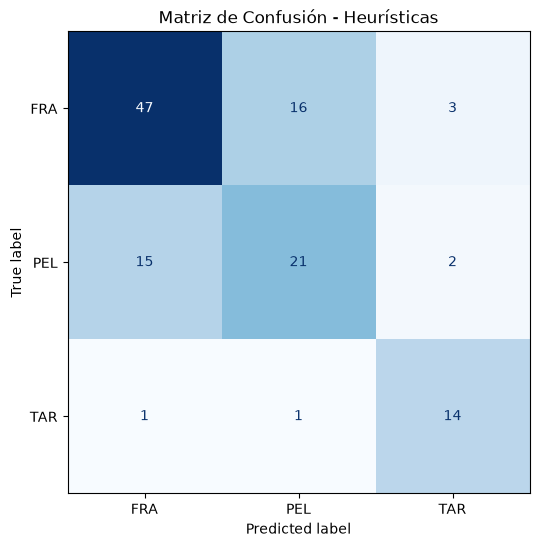

In [ ]:
# Cargar imagen de test en escala de grises
img_test = cv2.imread('assets/MPs_test.jpg')
gray_test = cv2.cvtColor(img_test, cv2.COLOR_BGR2GRAY)

# Cargar las anotaciones del CSV
df_test = pd.read_csv('assets/MPs_test_bbs.csv')

y_true = []
y_pred = []

# Recorrer el CSV fila por fila para recortar y clasificar
for index, row in df_test.iterrows():
    # Extraer coordenadas del CSV
    xmin = int(row['x_min'])
    ymin = int(row['y_min'])
    xmax = int(row['x_max'])
    ymax = int(row['y_max'])
    clase_real = str(row['label'])
    
    # Recortar la región exacta del plástico
    roi = gray_test[ymin:ymax, xmin:xmax]
    if roi.size == 0:
        continue

    # Segmentar con Otsu dentro del recorte
    _, thresh_roi = cv2.threshold(roi, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    contornos_roi, _ = cv2.findContours(thresh_roi, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if len(contornos_roi) > 0:
        # Extraer el contorno más grande (la partícula real, ignorando ruido)
        c_max = max(contornos_roi, key=cv2.contourArea)
        
        # Usar la función de la Celda 1 para sacar las medidas
        medidas = calcular_caracteristicas(c_max, roi)
        
        # Usar la función de la Celda 3 para adivinar
        # El asterisco desempaqueta la lista en los 5 argumentos de la función
        prediccion = clasificar_particula(*medidas)
        
        y_pred.append(prediccion)
        y_true.append(clase_real)

# Generar y dibujar la Matriz de Confusión
# Usamos set() para obtener los nombres únicos de las clases
etiquetas = sorted(list(set(y_true + y_pred))) 

cm = confusion_matrix(y_true, y_pred, labels=etiquetas)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=etiquetas)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
plt.title('Matriz de Confusión - Heurísticas')
plt.show()